<a href="https://colab.research.google.com/github/Srasti05/4IK25CS203_DAV_LAB/blob/main/4IK25CS203_EXP_09.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

EXP -09: Decision Tree Classifier: Building ,visualizing and evaluating a decision tree model on real world dataset

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier,plot_tree
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix


1. Load Dataset

In [ ]:
df= pd.read_csv('/content/Iris.csv')
print(df.head())
print("Shape:",df.shape)
print("Missing values", df.isnull().sum().sum())
print(df["Species"].value_counts())

   Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm      Species
0   1            5.1           3.5            1.4           0.2  Iris-setosa
1   2            4.9           3.0            1.4           0.2  Iris-setosa
2   3            4.7           3.2            1.3           0.2  Iris-setosa
3   4            4.6           3.1            1.5           0.2  Iris-setosa
4   5            5.0           3.6            1.4           0.2  Iris-setosa
Shape: (150, 6)
Missing values 0
Species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64


In [ ]:
X=df.drop(['Id','Species'],axis=1)
y=df['Species']

3.Split into training (80%) and testing (20%) data

In [ ]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

4.build the decision tree model (max_depth limits tree size to avoid overfitting)

In [ ]:
model = DecisionTreeClassifier(criterion="gini",max_depth=3,random_state=42)
model.fit(X_train, y_train)

DecisionTreeClassifier(max_depth=3, random_state=42)

5.Predict on test data

In [ ]:
y_pred=model.predict(X_test)

6. EVALUATE the model

In [ ]:
print("\n Accuracy :",accuracy_score(y_test,y_pred))
cm=confusion_matrix(y_test,y_pred)
print("\n Confusion Matrix :\n",cm)
print("\n Classification Report :\n",classification_report(y_test,y_pred))



 Accuracy : 0.9666666666666667

 Confusion Matrix :
 [[10  0  0]
 [ 0  9  1]
 [ 0  0 10]]

 Classification Report :
                  precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       1.00      0.90      0.95        10
 Iris-virginica       0.91      1.00      0.95        10

       accuracy                           0.97        30
      macro avg       0.97      0.97      0.97        30
   weighted avg       0.97      0.97      0.97        30



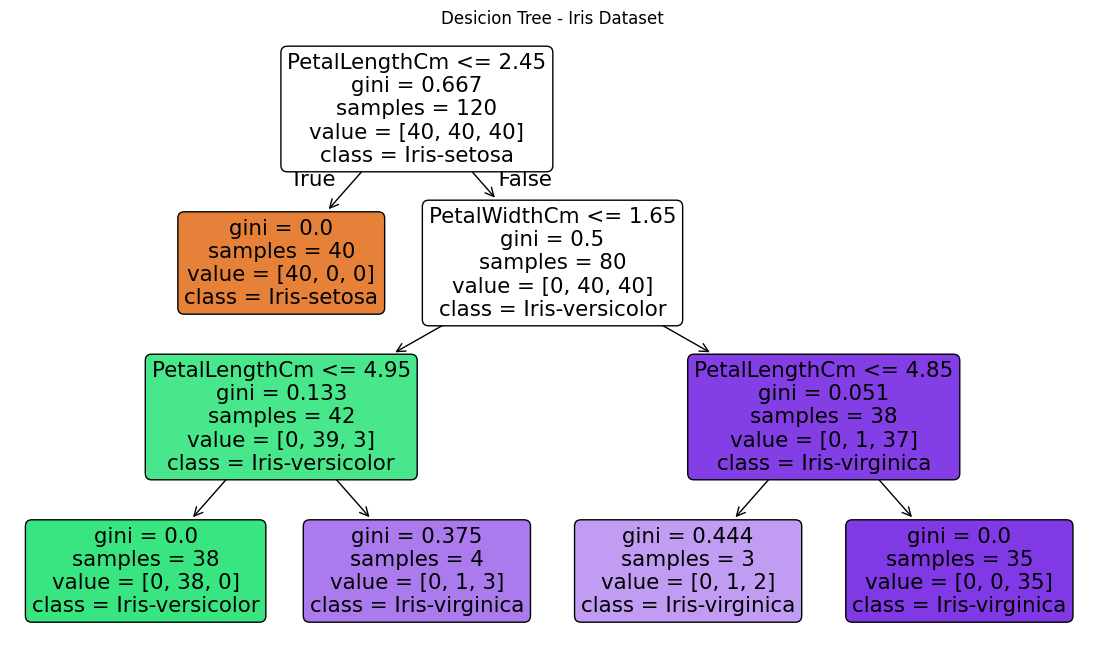

In [ ]:
plt.figure(figsize=(14,8))
plot_tree(model, feature_names=X.columns,class_names=model.classes_,filled=True,rounded=True)
plt.title("Desicion Tree - Iris Dataset")
plt.show()

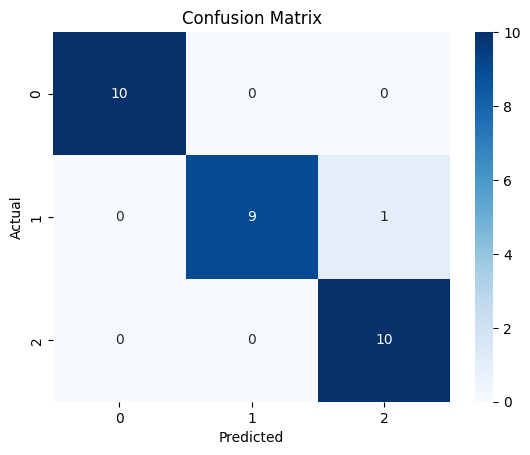

In [ ]:
sns.heatmap(cm,annot=True,fmt="d",cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

In [ ]:
print("\nFeature Importance:")
print(pd.Series(model.feature_importances_,index=X.columns).sort_values(ascending=False))


Feature Importance:
PetalLengthCm    0.579077
PetalWidthCm     0.420923
SepalWidthCm     0.000000
SepalLengthCm    0.000000
dtype: float64
